# Oxford-IIIT Pet: Pretrained Segmentation Model Comparison

Compare four models on the same test set:
- U-Net: existing Oxford-IIIT Pet checkpoint
- Mask R-CNN: COCO-pretrained instance segmentation
- DeepLabV3: VOC-category pretrained semantic segmentation
- FCN: VOC-category pretrained semantic segmentation

This is a zero-shot comparison for Mask R-CNN, DeepLabV3 and FCN against a U-Net already trained on Oxford-IIIT Pet. Keep `unet_oxford_pet.pth` beside this notebook and the dataset in `./data`.

## 1. Imports and configuration

In [1]:
import gc, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights, fcn_resnet50, FCN_ResNet50_Weights

SEED = 42
IMAGE_SIZE = (256, 256)
DATA_DIR = "./data"
UNET_PATH = "unet_oxford_pet.pth"
SCORE_THRESHOLD = 0.5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Check your NVIDIA driver and CUDA-enabled PyTorch.")
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda:0")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.7.1+cu128
Torchvision: 0.22.1+cu128
CUDA: 12.8
GPU: NVIDIA GeForce GTX 1650


## 2. Load Oxford-IIIT Pet test dataset

Foreground definition matches the U-Net experiment: mask labels 1 and 3 are foreground.

In [2]:
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor()
])

def mask_transform(mask):
    mask = TF.resize(mask, IMAGE_SIZE, interpolation=InterpolationMode.NEAREST)
    mask = TF.pil_to_tensor(mask)
    return ((mask == 1) | (mask == 3)).float()

test_dataset = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="test",
    target_types="segmentation",
    transform=image_transform,
    target_transform=mask_transform,
    download=False
)
print("Test samples:", len(test_dataset))

Test samples: 3669


## 3. Define U-Net and load existing checkpoint

The architecture must match the model used to create `unet_oxford_pet.pth`.

In [3]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1 = ConvBlock(in_channels, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.enc4 = ConvBlock(128, 256)
        self.bottleneck = ConvBlock(256, 512)
        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = ConvBlock(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = ConvBlock(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = ConvBlock(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, 2)
        self.dec1 = ConvBlock(64, 32)
        self.out = nn.Conv2d(32, out_channels, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

unet_model = UNet().to(device)
checkpoint = torch.load(UNET_PATH, map_location="cpu", weights_only=True)
unet_model.load_state_dict(checkpoint)
unet_model.eval()
print("U-Net checkpoint loaded:", UNET_PATH)

U-Net checkpoint loaded: unet_oxford_pet.pth


## 4. Shared evaluation function

Calculates global/micro Dice and IoU over the complete test set. Inference time is measured per image after one warm-up.

In [4]:
model_results = []
NUM_VISUAL_SAMPLES = min(4, len(test_dataset))
sample_results = []

for i in range(NUM_VISUAL_SAMPLES):
    image, mask = test_dataset[i]
    sample_results.append({
        "image": image,
        "ground_truth": mask[0] > 0,
        "predictions": {}
    })

def evaluate_model(name, model, predictor):
    intersection_total = 0
    prediction_total = 0
    target_total = 0
    inference_times = []

    _ = predictor(test_dataset[0][0])
    torch.cuda.synchronize()

    for idx in range(len(test_dataset)):
        image, mask = test_dataset[idx]
        ground_truth = mask[0] > 0

        torch.cuda.synchronize()
        start = time.perf_counter()
        prediction = predictor(image)
        torch.cuda.synchronize()
        inference_times.append(time.perf_counter() - start)

        prediction = prediction.detach().cpu().bool()
        intersection_total += (prediction & ground_truth).sum().item()
        prediction_total += prediction.sum().item()
        target_total += ground_truth.sum().item()

        if idx < NUM_VISUAL_SAMPLES:
            sample_results[idx]["predictions"][name] = prediction

        if (idx + 1) % 50 == 0:
            print(f"{name}: {idx + 1}/{len(test_dataset)}")

    dice = (2 * intersection_total + 1e-7) / (prediction_total + target_total + 1e-7)
    iou = (intersection_total + 1e-7) / (prediction_total + target_total - intersection_total + 1e-7)
    params = sum(p.numel() for p in model.parameters())
    avg_ms = np.mean(inference_times) * 1000

    model_results.append({
        "Model": name,
        "Dice": dice,
        "IoU": iou,
        "Inference Time (ms/image)": avg_ms,
        "Images/second": 1000 / avg_ms,
        "Parameters (M)": params / 1e6
    })
    print(f"{name} | Dice: {dice:.4f} | IoU: {iou:.4f} | {avg_ms:.2f} ms/image")

## 5. Evaluate U-Net

In [5]:
def predict_unet(image):
    image = image.unsqueeze(0).to(device)
    with torch.inference_mode():
        logits = unet_model(image)
        return torch.sigmoid(logits[0, 0]) >= 0.5

evaluate_model("U-Net", unet_model, predict_unet)

U-Net: 50/3669
U-Net: 100/3669
U-Net: 150/3669
U-Net: 200/3669
U-Net: 250/3669
U-Net: 300/3669
U-Net: 350/3669
U-Net: 400/3669
U-Net: 450/3669
U-Net: 500/3669
U-Net: 550/3669
U-Net: 600/3669
U-Net: 650/3669
U-Net: 700/3669
U-Net: 750/3669
U-Net: 800/3669
U-Net: 850/3669
U-Net: 900/3669
U-Net: 950/3669
U-Net: 1000/3669
U-Net: 1050/3669
U-Net: 1100/3669
U-Net: 1150/3669
U-Net: 1200/3669
U-Net: 1250/3669
U-Net: 1300/3669
U-Net: 1350/3669
U-Net: 1400/3669
U-Net: 1450/3669
U-Net: 1500/3669
U-Net: 1550/3669
U-Net: 1600/3669
U-Net: 1650/3669
U-Net: 1700/3669
U-Net: 1750/3669
U-Net: 1800/3669
U-Net: 1850/3669
U-Net: 1900/3669
U-Net: 1950/3669
U-Net: 2000/3669
U-Net: 2050/3669
U-Net: 2100/3669
U-Net: 2150/3669
U-Net: 2200/3669
U-Net: 2250/3669
U-Net: 2300/3669
U-Net: 2350/3669
U-Net: 2400/3669
U-Net: 2450/3669
U-Net: 2500/3669
U-Net: 2550/3669
U-Net: 2600/3669
U-Net: 2650/3669
U-Net: 2700/3669
U-Net: 2750/3669
U-Net: 2800/3669
U-Net: 2850/3669
U-Net: 2900/3669
U-Net: 2950/3669
U-Net: 3000/3669


## 6. Load and evaluate pretrained Mask R-CNN

COCO cat and dog instance masks are combined into one binary pet mask.

In [6]:
maskrcnn_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
maskrcnn_categories = maskrcnn_weights.meta["categories"]
maskrcnn_cat_id = maskrcnn_categories.index("cat")
maskrcnn_dog_id = maskrcnn_categories.index("dog")

maskrcnn_model = maskrcnn_resnet50_fpn(
    weights=maskrcnn_weights,
    min_size=256,
    max_size=256
).to(device)
maskrcnn_model.eval()

def predict_maskrcnn(image):
    with torch.inference_mode():
        output = maskrcnn_model([image.to(device)])[0]
    selected = (
        ((output["labels"] == maskrcnn_cat_id) | (output["labels"] == maskrcnn_dog_id))
        & (output["scores"] >= SCORE_THRESHOLD)
    )
    masks = output["masks"][selected]
    if len(masks) == 0:
        return torch.zeros(IMAGE_SIZE, dtype=torch.bool, device=device)
    return (masks[:, 0] >= 0.5).any(dim=0)

evaluate_model("Mask R-CNN", maskrcnn_model, predict_maskrcnn)
del maskrcnn_model
gc.collect()
torch.cuda.empty_cache()

Mask R-CNN: 50/3669
Mask R-CNN: 100/3669
Mask R-CNN: 150/3669
Mask R-CNN: 200/3669
Mask R-CNN: 250/3669
Mask R-CNN: 300/3669
Mask R-CNN: 350/3669
Mask R-CNN: 400/3669
Mask R-CNN: 450/3669
Mask R-CNN: 500/3669
Mask R-CNN: 550/3669
Mask R-CNN: 600/3669
Mask R-CNN: 650/3669
Mask R-CNN: 700/3669
Mask R-CNN: 750/3669
Mask R-CNN: 800/3669
Mask R-CNN: 850/3669
Mask R-CNN: 900/3669
Mask R-CNN: 950/3669
Mask R-CNN: 1000/3669
Mask R-CNN: 1050/3669
Mask R-CNN: 1100/3669
Mask R-CNN: 1150/3669
Mask R-CNN: 1200/3669
Mask R-CNN: 1250/3669
Mask R-CNN: 1300/3669
Mask R-CNN: 1350/3669
Mask R-CNN: 1400/3669
Mask R-CNN: 1450/3669
Mask R-CNN: 1500/3669
Mask R-CNN: 1550/3669
Mask R-CNN: 1600/3669
Mask R-CNN: 1650/3669
Mask R-CNN: 1700/3669
Mask R-CNN: 1750/3669
Mask R-CNN: 1800/3669
Mask R-CNN: 1850/3669
Mask R-CNN: 1900/3669
Mask R-CNN: 1950/3669
Mask R-CNN: 2000/3669
Mask R-CNN: 2050/3669
Mask R-CNN: 2100/3669
Mask R-CNN: 2150/3669
Mask R-CNN: 2200/3669
Mask R-CNN: 2250/3669
Mask R-CNN: 2300/3669
Mask R-C

## 7. Load and evaluate pretrained DeepLabV3

The pretrained semantic output has separate cat and dog classes; combine them into one pet foreground mask.

In [7]:
deeplab_weights = DeepLabV3_ResNet50_Weights.DEFAULT
deeplab_categories = deeplab_weights.meta["categories"]
deeplab_cat_id = deeplab_categories.index("cat")
deeplab_dog_id = deeplab_categories.index("dog")
deeplab_preprocess = deeplab_weights.transforms()

deeplab_model = deeplabv3_resnet50(weights=deeplab_weights).to(device)
deeplab_model.eval()

def predict_deeplab(image):
    processed = deeplab_preprocess(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        logits = deeplab_model(processed)["out"]
        logits = F.interpolate(logits, size=IMAGE_SIZE, mode="bilinear", align_corners=False)
        classes = logits.argmax(dim=1)[0]
        return (classes == deeplab_cat_id) | (classes == deeplab_dog_id)

evaluate_model("DeepLabV3", deeplab_model, predict_deeplab)
del deeplab_model
gc.collect()
torch.cuda.empty_cache()

DeepLabV3: 50/3669
DeepLabV3: 100/3669
DeepLabV3: 150/3669
DeepLabV3: 200/3669
DeepLabV3: 250/3669
DeepLabV3: 300/3669
DeepLabV3: 350/3669
DeepLabV3: 400/3669
DeepLabV3: 450/3669
DeepLabV3: 500/3669
DeepLabV3: 550/3669
DeepLabV3: 600/3669
DeepLabV3: 650/3669
DeepLabV3: 700/3669
DeepLabV3: 750/3669
DeepLabV3: 800/3669
DeepLabV3: 850/3669
DeepLabV3: 900/3669
DeepLabV3: 950/3669
DeepLabV3: 1000/3669
DeepLabV3: 1050/3669
DeepLabV3: 1100/3669
DeepLabV3: 1150/3669
DeepLabV3: 1200/3669
DeepLabV3: 1250/3669
DeepLabV3: 1300/3669
DeepLabV3: 1350/3669
DeepLabV3: 1400/3669
DeepLabV3: 1450/3669
DeepLabV3: 1500/3669
DeepLabV3: 1550/3669
DeepLabV3: 1600/3669
DeepLabV3: 1650/3669
DeepLabV3: 1700/3669
DeepLabV3: 1750/3669
DeepLabV3: 1800/3669
DeepLabV3: 1850/3669
DeepLabV3: 1900/3669
DeepLabV3: 1950/3669
DeepLabV3: 2000/3669
DeepLabV3: 2050/3669
DeepLabV3: 2100/3669
DeepLabV3: 2150/3669
DeepLabV3: 2200/3669
DeepLabV3: 2250/3669
DeepLabV3: 2300/3669
DeepLabV3: 2350/3669
DeepLabV3: 2400/3669
DeepLabV3: 2

## 8. Load and evaluate pretrained FCN

In [8]:
fcn_weights = FCN_ResNet50_Weights.DEFAULT
fcn_categories = fcn_weights.meta["categories"]
fcn_cat_id = fcn_categories.index("cat")
fcn_dog_id = fcn_categories.index("dog")
fcn_preprocess = fcn_weights.transforms()

fcn_model = fcn_resnet50(weights=fcn_weights).to(device)
fcn_model.eval()

def predict_fcn(image):
    processed = fcn_preprocess(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        logits = fcn_model(processed)["out"]
        logits = F.interpolate(logits, size=IMAGE_SIZE, mode="bilinear", align_corners=False)
        classes = logits.argmax(dim=1)[0]
        return (classes == fcn_cat_id) | (classes == fcn_dog_id)

evaluate_model("FCN", fcn_model, predict_fcn)
del fcn_model
gc.collect()
torch.cuda.empty_cache()

FCN: 50/3669
FCN: 100/3669
FCN: 150/3669
FCN: 200/3669
FCN: 250/3669
FCN: 300/3669
FCN: 350/3669
FCN: 400/3669
FCN: 450/3669
FCN: 500/3669
FCN: 550/3669
FCN: 600/3669
FCN: 650/3669
FCN: 700/3669
FCN: 750/3669
FCN: 800/3669
FCN: 850/3669
FCN: 900/3669
FCN: 950/3669
FCN: 1000/3669
FCN: 1050/3669
FCN: 1100/3669
FCN: 1150/3669
FCN: 1200/3669
FCN: 1250/3669
FCN: 1300/3669
FCN: 1350/3669
FCN: 1400/3669
FCN: 1450/3669
FCN: 1500/3669
FCN: 1550/3669
FCN: 1600/3669
FCN: 1650/3669
FCN: 1700/3669
FCN: 1750/3669
FCN: 1800/3669
FCN: 1850/3669
FCN: 1900/3669
FCN: 1950/3669
FCN: 2000/3669
FCN: 2050/3669
FCN: 2100/3669
FCN: 2150/3669
FCN: 2200/3669
FCN: 2250/3669
FCN: 2300/3669
FCN: 2350/3669
FCN: 2400/3669
FCN: 2450/3669
FCN: 2500/3669
FCN: 2550/3669
FCN: 2600/3669
FCN: 2650/3669
FCN: 2700/3669
FCN: 2750/3669
FCN: 2800/3669
FCN: 2850/3669
FCN: 2900/3669
FCN: 2950/3669
FCN: 3000/3669
FCN: 3050/3669
FCN: 3100/3669
FCN: 3150/3669
FCN: 3200/3669
FCN: 3250/3669
FCN: 3300/3669
FCN: 3350/3669
FCN: 3400/3669


## 9. Quantitative comparison

In [9]:
results_df = pd.DataFrame(model_results).sort_values("Dice", ascending=False).reset_index(drop=True)
display(results_df.round(4))
print("Best Dice:", results_df.loc[results_df["Dice"].idxmax(), "Model"])
print("Best IoU:", results_df.loc[results_df["IoU"].idxmax(), "Model"])

,Model,Dice,IoU,Inference Time (ms/image),Images/second,Parameters (M)
0,DeepLabV3,0.9153,0.8438,198.0705,5.0487,42.0041
1,Mask R-CNN,0.8967,0.8127,64.8542,15.4192,44.4014
2,FCN,0.8882,0.7988,133.1947,7.5078,35.3222
3,U-Net,0.8590,0.7528,11.6099,86.1333,7.7660


Best Dice: DeepLabV3
Best IoU: DeepLabV3


## 10. Visual comparison on the same test images

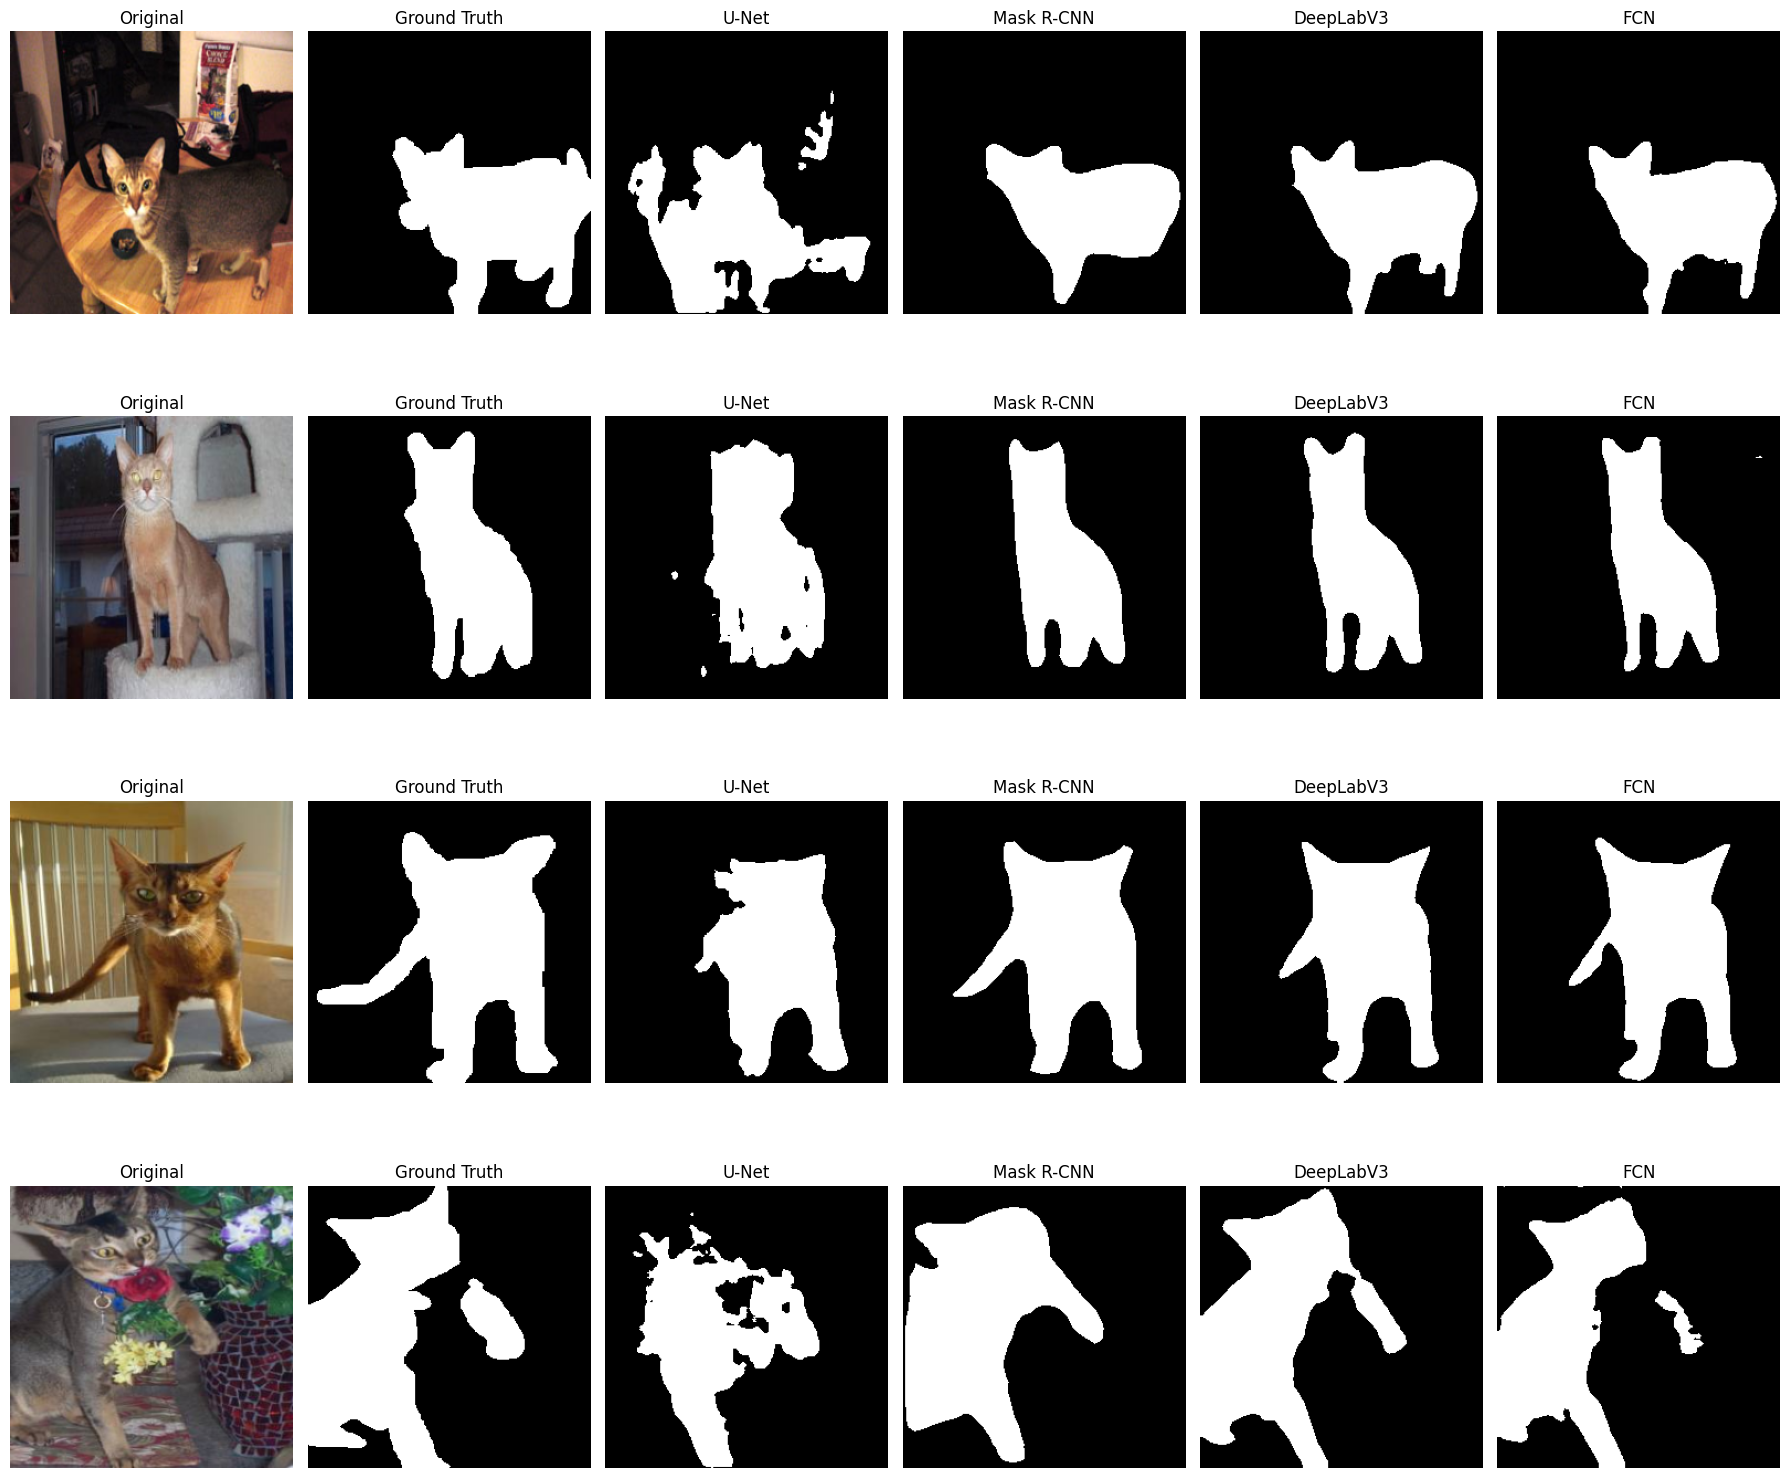

In [10]:
model_names = ["U-Net", "Mask R-CNN", "DeepLabV3", "FCN"]
fig, axes = plt.subplots(NUM_VISUAL_SAMPLES, 6, figsize=(18, 4 * NUM_VISUAL_SAMPLES), squeeze=False)

for i, sample in enumerate(sample_results):
    axes[i, 0].imshow(sample["image"].permute(1, 2, 0))
    axes[i, 0].set_title("Original")
    axes[i, 1].imshow(sample["ground_truth"], cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    for j, name in enumerate(model_names):
        axes[i, j + 2].imshow(sample["predictions"][name], cmap="gray")
        axes[i, j + 2].set_title(name)

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 11. Metric comparison charts

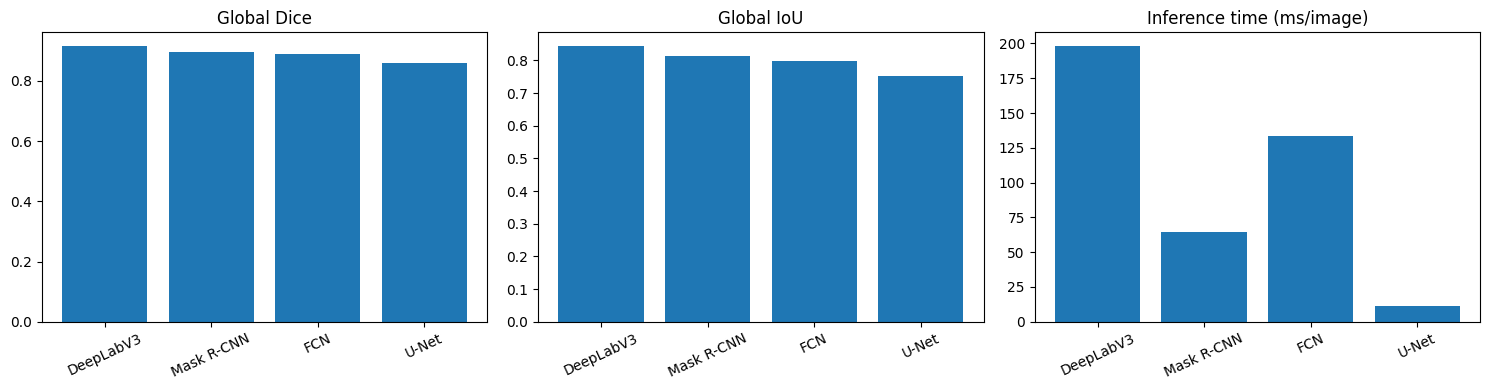

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(results_df["Model"], results_df["Dice"])
axes[0].set_title("Global Dice")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(results_df["Model"], results_df["IoU"])
axes[1].set_title("Global IoU")
axes[1].tick_params(axis="x", rotation=25)

axes[2].bar(results_df["Model"], results_df["Inference Time (ms/image)"])
axes[2].set_title("Inference time (ms/image)")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## Notes

- U-Net uses your Oxford-IIIT Pet-trained checkpoint.
- Mask R-CNN uses COCO-pretrained weights; detected cat/dog instance masks are combined.
- DeepLabV3 and FCN use pretrained semantic segmentation weights; cat/dog classes are combined.
- Dice and IoU are global pixel-level metrics over the test set.
- Inference time includes model preprocessing inside each predictor, but excludes dataset loading and visualization.
- This is not an equal-training comparison: only U-Net has been trained on Oxford-IIIT Pet.
- The first run may download pretrained weights. Keep an internet connection available.